In [1]:
#Importing from the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#This whole cell is used for importing and I reading data that I was given
#As we can see I used Pandas because it helps read the parquet data
#Numpy I use as a calculator basically
#Matplotlib is so I can make graphs
data = pd.read_parquet("software-data.parquet") #This is used to load the data for the FS-3 vehicle data
data = data.sort_values("Time")
data = data.drop_duplicates(subset="Time")
data = data.ffill().reset_index(drop=True) #This is used to basically say that if there are an missing values they fill it up so its not at big because the car has multiple sensors that update depending on the different times, luckily if I didnt go to office I would realize how good it is cuz holy
gear_ratio = 12 / 41 #This math is used so I need the vehicle's speed in meters per second and miles based of the moter speed to RPM
wheel_radius = 0.2 #The formula I used is v = RPM x 12/41 * 2pi/60 * .2
data["speed_mps"] = (
    data["SME_TRQSPD_Speed"].abs()
    * gear_ratio
    * (2 * np.pi / 60) 
    * wheel_radius
)
data["speed_mph"] = data["speed_mps"] * 2.23694
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["Time", "speed_mps"])
data = data.reset_index(drop=True)
print("Rows:", len(data))
print("Columns:", len(data.columns))
print(data.head(10).to_string())
#So the gear ratio gives the wheel's speed when rotating obv. Then I converted the RPM into RPS (Radians per second) Then I multipled by wheel radius which gives the vehicles linear speed using the formula VMPH = Vm/s * 2.23694

Rows: 13838
Columns: 257
       Time  SME_THROTL_TorqueDemand  SME_THROTL_MaxSpeed  SME_THROTL_Forward  SME_THROTL_Reverse  SME_THROTL_UNUSED_BIT_1  SME_THROTL_PowerReady  SME_THROTL_UNUSED_BIT_2  SME_THROTL_UNUSED_BIT_3  SME_THROTL_UNUSED_BIT_4  SME_THROTL_UNUSED_BIT_5  SME_THROTL_MBB_Alive  SME_THROTL_UNUSED_BIT_6  SME_THROTL_UNUSED_BIT_7  SME_THROTL_UNUSED_BIT_8  SME_THROTL_UNUSED_BIT_9  SME_THROTL_UNUSED_SHORT_1  SME_CURRLIM_ChargeCurrentLim  SME_CURRLIM_DischargeCurrentLim  SME_CURRLIM_UNUSED_INT_1  SME_TRQSPD_Speed  SME_TRQSPD_Torque  SME_TRQSPD_SOC_Low_Traction  SME_TRQSPD_SOC_Low_Hydraulic  SME_TRQSPD_Reverse  SME_TRQSPD_Forward  SME_TRQSPD_Park_Brake  SME_TRQSPD_Pedal_Brake  SME_TRQSPD_Controller_Overtermp  SME_TRQSPD_Key_switch_overvolt  SME_TRQSPD_Key_switch_undervolt  SME_TRQSPD_Running  SME_TRQSPD_Traction  SME_TRQSPD_Hydraulic  SME_TRQSPD_Powering_Enabled  SME_TRQSPD_Powering_Ready  SME_TRQSPD_Precharging  SME_TRQSPD_contactor_closed  SME_TRQSPD_MotorFlags  SME_TEMP_Motor

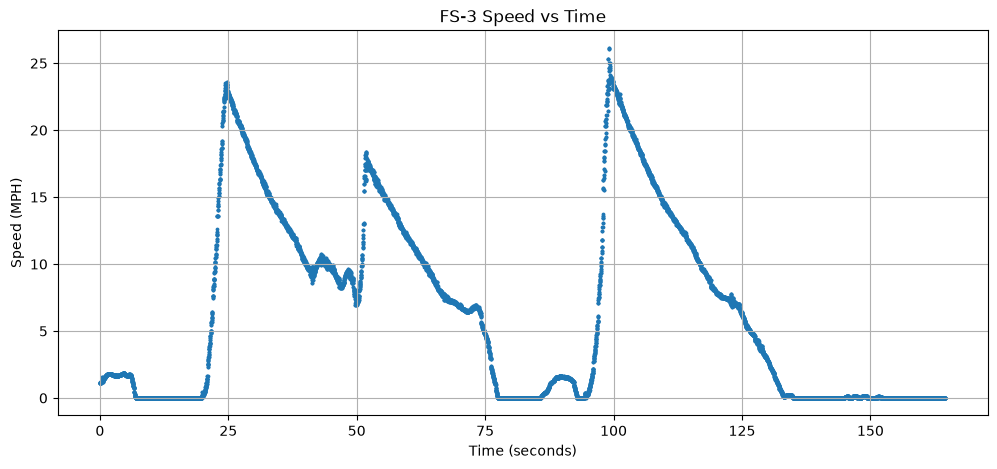

Speed near 10 seconds: 0.0 MPH
Maximum speed: 26.135645735830863 MPH


In [2]:
#The difference between Speed vs Time
plt.figure(figsize=(12, 5)) #I used pt.scatter() instead of a regular line graph so each dot represents a recorded data point
#I lowkey did this cuz the graph helps me see when the car waas moving quickly or slowing down or accelerating up or stopping
plt.scatter(
    data["Time"],
    data["speed_mph"],
    s=3
)
plt.xlabel("Time (seconds)")
plt.ylabel("Speed (MPH)")
plt.title("FS-3 Speed vs Time")
plt.grid()
plt.show()
# This finds the speed at 10 seconds, basically Difference = the absolute value of t - 10 which basically makes it where the smallest difference was selected which gives the measurement closest to 10 seconds, basically rounding up
i = (data["Time"] - 10).abs().idxmin() #This is helpful cuz it basically shows every individual data points
print("Speed near 10 seconds:",
      data.loc[i, "speed_mph"], "MPH")
print("Maximum speed:",
      data["speed_mph"].max(), "MPH")

In [3]:
#Doing math to accelerate and find out driving states
data["smooth_speed"] = (
    data["speed_mps"]
    .rolling(25, center=True, min_periods=1)#Acceleration is the rate at which velocity changes over time. a = Deltav / Deltat
    .mean()
)
data["acceleration"] = np.gradient( #This is used so the estimates the rate of speed change at each recorded time rather than calculating just one acceleration for the entire run
    data["smooth_speed"],
    data["Time"]
)
data["smooth_acceleration"] = ( #Then I smooth the speed which basically calculates a moving average of approximately 25 nearby readings, though if there were real sensor data can fluctuate slightly due to noise. Smoothing lests the flucuation reduces so acceleration esitmate are less affected by small measurement errors
    data["acceleration"]
    .rolling(25, center=True, min_periods=1) 
    .mean()
)
pedal = data["ETC_STATUS_PEDAL_TRAVEL"].fillna(0)
brake_cols = [
    c for c in [
        "TMAIN_DATA_BRAKES_F",
        "TMAIN_DATA_BRAKES_R"
    ]
    if c in data.columns
]
if brake_cols:
    pressure = data[brake_cols].clip(lower=0).max(axis=1)
    low = pressure.quantile(0.10)
    high = pressure.quantile(0.90)
    brake_threshold = low + 0.10 * (high - low)
    braking_signal = (
        (pressure > brake_threshold) &
        (high > low)
    )
    print("Brake pressure threshold:", brake_threshold)
else:
    braking_signal = pd.Series(False, index=data.index)
    print("WARNING: No brake pressure columns found.")
if "SME_THROTL_TorqueDemand" in data.columns:
    torque = data["SME_THROTL_TorqueDemand"].fillna(0)
    torque_tolerance = max(
        1.0,
        torque.abs().quantile(0.90) * 0.03
    )
    low_torque = torque.abs() <= torque_tolerance
    print("Torque tolerance:", torque_tolerance)
else:
    low_torque = pd.Series(True, index=data.index)
    print("WARNING: Motor torque signal not found.")
accelerating = (
    (pedal > 1) &
    (data["smooth_acceleration"] > 0.1)
)
braking = (
    braking_signal &
    (data["smooth_acceleration"] < -0.1)
)
coasting = (
    (pedal <= 1) &
    low_torque &
    ~braking_signal &
    (data["smooth_acceleration"] < -0.1) &
    (data["speed_mps"] > 0.5)
)
data["state"] = np.select(
    [braking, accelerating, coasting],
    ["Braking", "Accelerating", "Coasting"],
    default="Other"
)
print(data["state"].value_counts())

Brake pressure threshold: 0.031041757389903068
Torque tolerance: 7.949999999999999
state
Other           6310
Braking         4126
Coasting        2272
Accelerating    1130
Name: count, dtype: int64


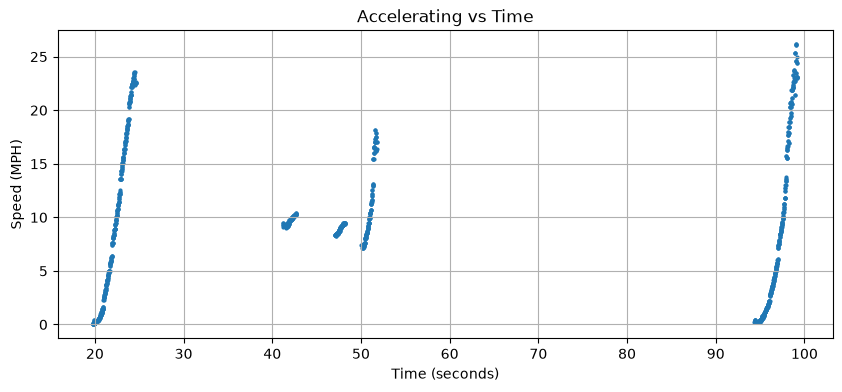

Accelerating readings: 1130


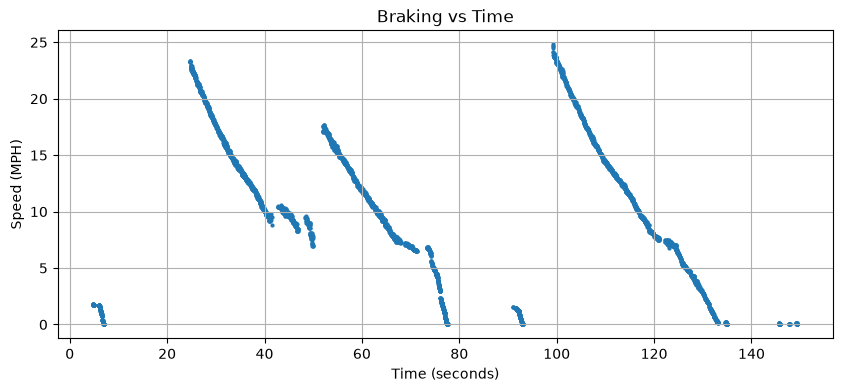

Braking readings: 4126


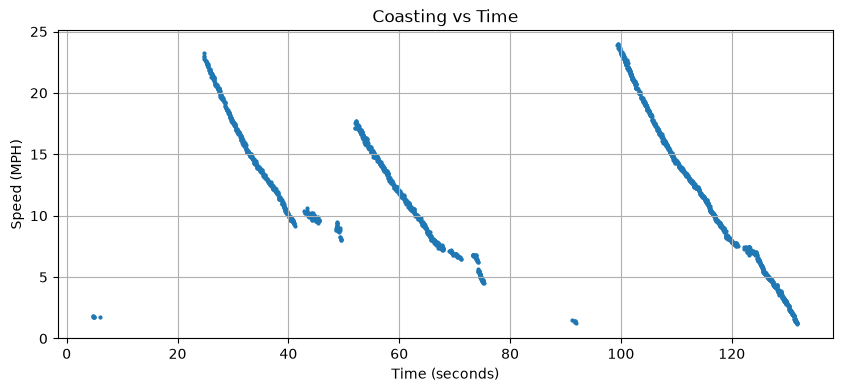

Coasting readings: 2272


In [4]:
#Graphing the driving states this basically makes it where I created three separate scatter plots for accelerating, braking, and coasting
for state in ["Accelerating", "Braking", "Coasting"]:
    subset = data[data["state"] == state] 
    plt.figure(figsize=(10, 4))
    plt.scatter(
        subset["Time"],
        subset["speed_mph"],
        s=4
    )# I separated the vehicles driving states into three graphs. This helped me compare how speed changed during estimated acceleration, braking, and coasting
    plt.xlabel("Time (seconds)") #The graphs make it easier to understand when each driving state occurred and at what speed
    plt.ylabel("Speed (MPH)")
    plt.title(state + " vs Time")
    plt.grid()
    plt.show()
    print(state, "readings:", len(subset)) #The code uses the driving state conditions from the CEll above to select which data points appear in each graph

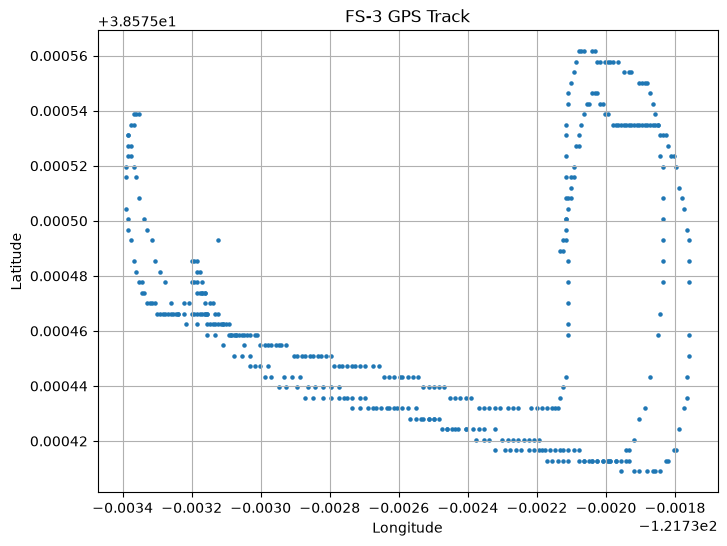

Unique GPS positions: 419


In [5]:
# Estimating the number of laps needed, so I used the first valid GPS location as a reference point so that I could calculate how far each later GPS positions was from the starting point
gps = data[
    ["Time", "VDM_GPS_Latitude", "VDM_GPS_Longitude"] #The code uses the Haversine formula which basically has it where it estimates the distance between two positions on the curved surface (Shout out to reddit) This formula I used because the Latitiude and longitude are are angular coordinates no meters. The Haversine formula converts their differences into an approximate distance
].dropna().copy()
gps = gps[
    gps["VDM_GPS_Latitude"].between(-90, 90) &
    gps["VDM_GPS_Longitude"].between(-180, 180) &
    (gps["VDM_GPS_Latitude"] != 0) &
    (gps["VDM_GPS_Longitude"] != 0)
]
gps = gps.loc[
    gps[
        ["VDM_GPS_Latitude", "VDM_GPS_Longitude"]
    ].ne(
        gps[
            ["VDM_GPS_Latitude", "VDM_GPS_Longitude"]
        ].shift()
    ).any(axis=1)
].reset_index(drop=True)
plt.figure(figsize=(8, 6))
plt.scatter(
    gps["VDM_GPS_Longitude"],
    gps["VDM_GPS_Latitude"],
    s=5
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("FS-3 GPS Track")
plt.grid()
plt.show()
print("Unique GPS positions:", len(gps))

In [6]:
#Calculating statistics for each lap
lap_times = []
if len(gps) >= 2:
#What I did was estimate the lap I calculated which is Lap duration, Max Speed, Max acceleration, How long it takes to accelerate and time it is takened to coasting
    lat0 = np.radians(gps["VDM_GPS_Latitude"].iloc[0])
    lon0 = np.radians(gps["VDM_GPS_Longitude"].iloc[0])
    lat = np.radians(gps["VDM_GPS_Latitude"])
    lon = np.radians(gps["VDM_GPS_Longitude"])
    a = (
        np.sin((lat - lat0) / 2) ** 2 +
        np.cos(lat0) * np.cos(lat) *
        np.sin((lon - lon0) / 2) ** 2
    )
    distance = 2 * 6371000 * np.arcsin(np.sqrt(a))
    gps["distance_from_start"] = distance
    start_time = gps["Time"].iloc[0]
    crossings = [start_time]
    went_away = False
    for t, d in zip(gps["Time"], distance):
        if d >= 80:
            went_away = True
        if (
            went_away and
            d <= 20 and
            t - crossings[-1] >= 15
        ):
            crossings.append(t)
            went_away = False
    lap_times = list(zip(crossings[:-1], crossings[1:]))
print("Estimated completed laps:", len(lap_times))
for number, (start, end) in enumerate(lap_times, 1):
    print(
        f"Lap {number}: "
        f"{start:.2f}s to {end:.2f}s "
        f"({end-start:.2f}s)"
    )

Estimated completed laps: 1
Lap 1: 0.00s to 61.62s (61.62s)


In [7]:
#This is basically used cuz I had a error with my coastdown luckily this fixed it 
lap_results = []
for number, (start, end) in enumerate(lap_times, 1):
    lap = data[
        (data["Time"] >= start) &
        (data["Time"] < end)
    ].copy() #A coastdown test studies how a car slows down when it isnt being driven forward by the motor or actively braked, we can estimate the effect of the drag and rolling resistance
    if lap.empty:
        continue
    lap["dt"] = (
        lap["Time"].shift(-1) - lap["Time"]
    ).fillna(0)
    lap_results.append({
        "Lap": number,
        "Lap Time (s)": end - start,
        "Max Speed (MPH)": lap["speed_mph"].max(),
        "Max Acceleration (m/s²)": lap["smooth_acceleration"].max(),
        "Accelerating Time (s)": lap.loc[
            lap["state"] == "Accelerating", "dt"
        ].sum(),
        "Coasting Time (s)": lap.loc[
            lap["state"] == "Coasting", "dt"
        ].sum()
    })
lap_results = pd.DataFrame(lap_results)
if len(lap_results):
    print(lap_results.to_string(index=False))
else:
    print("No completed laps identified. Check Step 4.")

 Lap  Lap Time (s)  Max Speed (MPH)  Max Acceleration (m/s²)  Accelerating Time (s)  Coasting Time (s)
   1     61.616135        23.571445                 7.230704               8.839631          10.432706


In [8]:
brake_limit = 0.04 #So I printed the diagnostic information this was used because I had an error where no coastdown data and this helps me find the issue is found and lowkey it works
valid = (
    (data["speed_mps"] >= 5) &
    (data["ETC_STATUS_PEDAL_TRAVEL"] <= 1) &
    (data["SME_THROTL_TorqueDemand"].abs() <= 1) &
    (data["TMAIN_DATA_BRAKES_F"] < brake_limit) &
    (data["TMAIN_DATA_BRAKES_R"] < brake_limit)
)
in_lap = pd.Series(False, index=data.index)
for start, end in lap_times:
    in_lap |= data["Time"].between(start, end)
valid = valid & in_lap
groups = valid.ne(valid.shift(fill_value=False)).cumsum() 
coast_segments = []
for _, segment in data[valid].groupby(groups[valid]):
    duration = (
        segment["Time"].iloc[-1] -
        segment["Time"].iloc[0]
    )
    speed_change = (
        segment["speed_mps"].iloc[-1] -
        segment["speed_mps"].iloc[0]
    )
    if duration >= 1 and speed_change < 0:
        coast_segments.append(segment.copy())
print("Possible coastdown segments:", len(coast_segments))
print("Total coastdown points:",
      sum(len(s) for s in coast_segments))

Possible coastdown segments: 2
Total coastdown points: 1945


In [9]:
#This is a calculator for drag and rolling resistance which I use v^2 and dv/dt which is x axis of speed square and y axis is aceleration
print("=== FS-3 COASTDOWN CHECK ===")
print("Laps:", len(lap_times))
print("\nDriving states:")
print(data["state"].value_counts())
print("\nSpeed above 5 m/s:")
print((data["speed_mps"] >= 5).sum())
print("\nPedal released above 5 m/s:")#Notice that drag force depends on speed squared which basically allows speed doubles but have drag becomes approximatly four times as large which makes the assumption that the other values stay the same
print((
    (data["speed_mps"] >= 5) &
    (data["ETC_STATUS_PEDAL_TRAVEL"] <= 1)
).sum())
print("\nSpeed decreasing above 5 m/s:")
print((
    (data["speed_mps"] >= 5) &
    (data["smooth_acceleration"] < -0.1)
).sum())
print("\nPossible coasting readings:")
possible = (
    (data["speed_mps"] >= 5) &
    (data["ETC_STATUS_PEDAL_TRAVEL"] <= 1) &
    (data["smooth_acceleration"] < -0.1)
)
print(possible.sum())
print("\nMotor torque statistics:")
if "SME_THROTL_TorqueDemand" in data.columns:
    print(data.loc[possible, "SME_THROTL_TorqueDemand"].describe())
print("\nBrake pressure statistics:")
for col in ["TMAIN_DATA_BRAKES_F", "TMAIN_DATA_BRAKES_R"]:
    if col in data.columns:
        print(col)
        print(data.loc[possible, col].describe())

=== FS-3 COASTDOWN CHECK ===
Laps: 1

Driving states:
state
Other           6310
Braking         4126
Coasting        2272
Accelerating    1130
Name: count, dtype: int64

Speed above 5 m/s:
3685

Pedal released above 5 m/s:
3284

Speed decreasing above 5 m/s:
3295

Possible coasting readings:
3247

Motor torque statistics:
count    3247.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: SME_THROTL_TorqueDemand, dtype: float64

Brake pressure statistics:
TMAIN_DATA_BRAKES_F
count    3247.000000
mean        0.030404
std         0.001878
min         0.018777
25%         0.029575
50%         0.030542
75%         0.031429
max         0.036022
Name: TMAIN_DATA_BRAKES_F, dtype: float64
TMAIN_DATA_BRAKES_R
count    3247.000000
mean        0.030688
std         0.001949
min         0.022081
25%         0.029897
50%         0.030945
75%         0.031832
max         0.036747
Name: TMAIN_DATA_BRAKES_R, dtype: float64


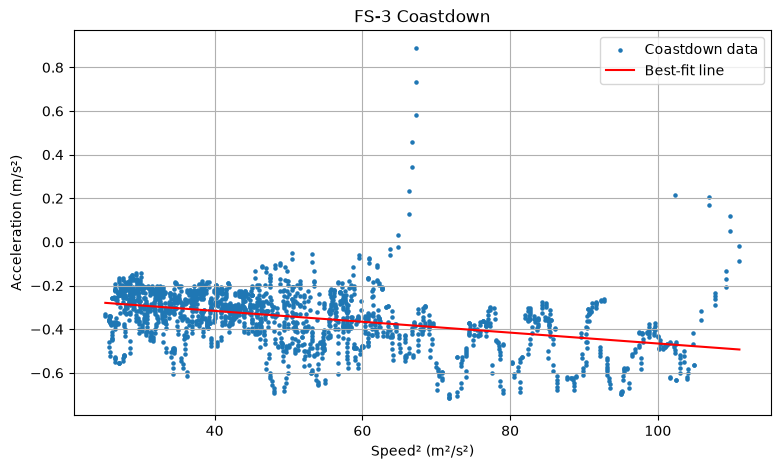

Slope: -0.0024907277840663924
Intercept: -0.21641828625466417
CdA: 0.9925499388325307 m²
Crr: 0.024320893410683025


In [10]:

if len(coast_segments) == 0:
    print("No valid coastdown data.") #If you cant tell I have it where if there is no data this happens cuz you never know this could be used again
else:
    coast = pd.concat(
        coast_segments,
        ignore_index=True
    )
    x = coast["speed_mps"] ** 2
    y = coast["smooth_acceleration"]
    valid_points = (
        np.isfinite(x) &
        np.isfinite(y)
    )
    x = x[valid_points]
    y = y[valid_points]
    if len(x) < 2 or x.nunique() < 2:
        print("Not enough varied speed data for fitting.") #During an ideal coastdown drag and rolling resistance act against the car's motion 
    else:
        slope, intercept = np.polyfit(x, y, 1)
        plt.figure(figsize=(9, 5))
        plt.scatter(
            x, y,
            s=5,
            label="Coastdown data"
        )
        x_line = np.linspace(x.min(), x.max(), 100)
        plt.plot(
            x_line,
            slope * x_line + intercept,
            color="red",
            label="Best-fit line"
        ) # I used np.polyfit() cuz real world data is noisy and the points usually dont lie perfectly on one straight line and this code basically uses a line that minimizes the sum of squared vertical differences between the data points and the line, 
        plt.xlabel("Speed² (m²/s²)") #Though  have to say this code uses smoothed acceleration rather than having it calculated independely within each coastdown segment. It does reduce noices but the values near the boundaries of the segment can be influced by the non coasting readings if they neighbor them
        plt.ylabel("Acceleration (m/s²)")
        plt.title("FS-3 Coastdown")
        plt.legend()
        plt.grid()
        plt.show()
        # Given project constants
        mass = 221.4
        effective_mass = 244.08
        rho = 1.225
        g = 9.81
        CdA = -2 * slope * effective_mass / rho
        Crr = (
            -intercept * effective_mass /
            (mass * g)
        )
        print("Slope:", slope)
        print("Intercept:", intercept)
        print("CdA:", CdA, "m²")
        print("Crr:", Crr)


In [ ]:
#As a person who has not truly analyzed data collected from the FS-3 car. I used python to read the parquet file and calculate the speed of the car from the motor RPM. I then use the speed vs time graph so that I can observe how the vehicles speed changed during the recording. At approximatly 10 seconds the 0 MPH. So there needs to have a showed period when the vehicle accelerated or if its slowed down or its stopped.

In [ ]:
#I noticed that the accelerator, brake and motor can be used to investigate the car's driving behavior and I make an estimation on lap times also using GPS data. One thing that was difficult though was that the brake light signal appeared active during almost the entire moving portion of the recording. It became not reliable on its own for identifying braking. So then I used signals to identify the possible acceleration, braking, and coasting, though I would say it needs verify.

In [ ]:
#The coastdown was the hardest part because everything I did, didnt work, until I go on reddit and ask for help and I found out that I need to isolate periods when the vehicle was traveling above 5 m/s and slowing continously for at least one second. It was used to be honest as a way so I can see the connection between acceleration and speed squared so that drag area and rolling resistance can be estimated. This project demonstates new problems I need to solve and about vehicle data and what I need more to learn.